<a href="https://colab.research.google.com/github/sayalipatil2005/WaferLens-Active-Learning-Driven-Framework-for-Semiconductor-Wafer-Defect-Classification/blob/main/01_Dataset_Exploration_WaferLens.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# WaferLens
## Notebook 01: WM-811K Dataset Exploration

Research: Active Learning for Semiconductor Wafer Defect Classification

Objective:
Understand the WM-811K dataset, inspect its structure,
analyse defect labels and visualise wafer maps.

Status: Initial exploration

In [1]:
print("Welcome to WaferWise AI!")
print("Research: Semiconductor Wafer Defect Classification")
print("Dataset: WM-811K")

Welcome to WaferWise AI!
Research: Semiconductor Wafer Defect Classification
Dataset: WM-811K


In [2]:
!pip install numpy pandas matplotlib seaborn scikit-learn

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
!pip install -q kaggle

from google.colab import userdata
import os

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

print("Kaggle authentication configured successfully!")

Kaggle authentication configured successfully!


In [5]:
import os

os.makedirs("/content/waferwise_data", exist_ok=True)

!kaggle datasets download -d qingyi/wm811k-wafer-map -p /content/waferwise_data

Dataset URL: https://www.kaggle.com/datasets/qingyi/wm811k-wafer-map
License(s): CC0-1.0
100% 149M/149M [00:01<00:00, 104MB/s] 



In [6]:
import zipfile
import os

zip_path = "/content/waferwise_data/wm811k-wafer-map.zip"
extract_path = "/content/waferwise_data/extracted"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print(os.listdir(extract_path))

Dataset extracted successfully!
['LSWMD.pkl']


In [7]:
for root, dirs, files in os.walk(extract_path):
    for file in files:
        print(os.path.join(root, file))

/content/waferwise_data/extracted/LSWMD.pkl


In [8]:
import pandas as pd
import os

dataset_path = "/content/waferwise_data/extracted/LSWMD.pkl"

df = pd.read_pickle(dataset_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

Dataset loaded successfully!
Shape: (811457, 6)

First 5 rows:


,waferMap,dieSize,lotName,waferIndex,trianTestLabel,failureType
0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,1.0,[[Training]],[[none]]
1,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,2.0,[[Training]],[[none]]
2,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,3.0,[[Training]],[[none]]
3,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,4.0,[[Training]],[[none]]
4,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,5.0,[[Training]],[[none]]


In [9]:
import numpy as np
import pandas as pd

# Extract readable labels from nested arrays
def extract_label(value):
    arr = np.asarray(value, dtype=object).ravel()
    if arr.size == 0:
        return np.nan
    return arr[0]

failure_labels = df["failureType"].apply(extract_label)
split_labels = df["trianTestLabel"].apply(extract_label)

print("DEFECT CATEGORY DISTRIBUTION")
print(failure_labels.value_counts(dropna=False))

print("\nTRAINING / TEST DISTRIBUTION")
print(split_labels.value_counts(dropna=False))

DEFECT CATEGORY DISTRIBUTION
failureType
NaN          638507
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64

TRAINING / TEST DISTRIBUTION
trianTestLabel
NaN         638507
Test        118595
Training     54355
Name: count, dtype: int64


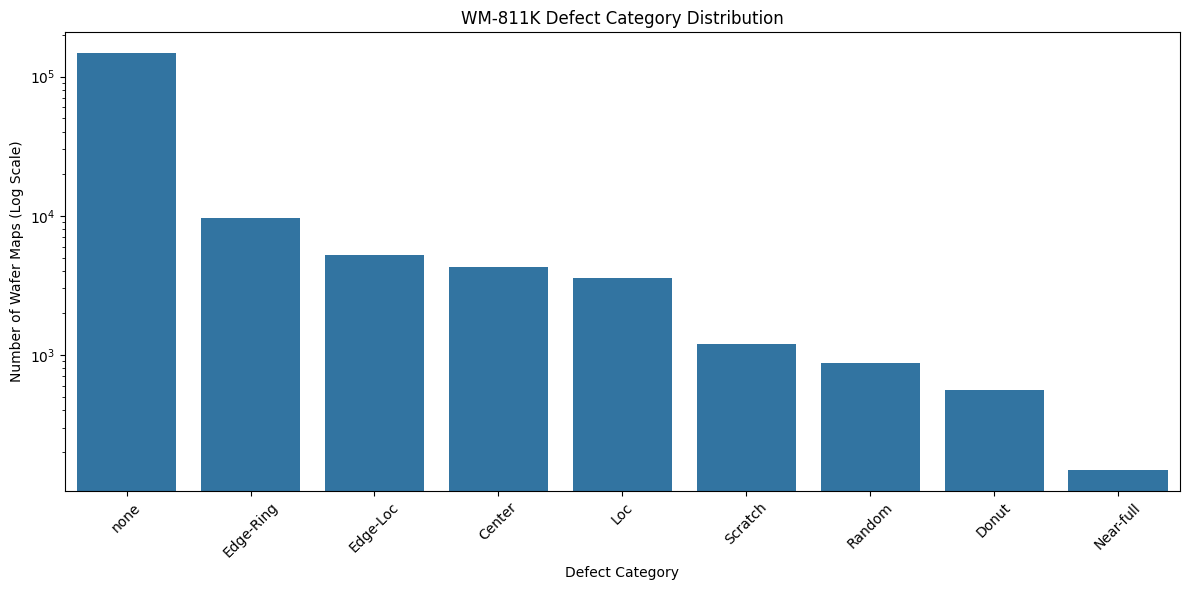

In [10]:
# Remove missing labels
label_counts = failure_labels.dropna().value_counts()

# Plot defect distribution
plt.figure(figsize=(12, 6))

sns.barplot(
    x=label_counts.index,
    y=label_counts.values
)

plt.yscale("log")
plt.title("WM-811K Defect Category Distribution")
plt.xlabel("Defect Category")
plt.ylabel("Number of Wafer Maps (Log Scale)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

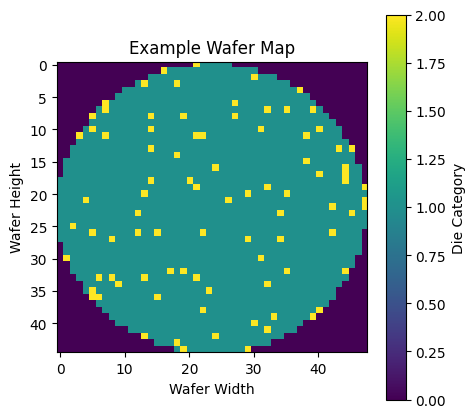

In [11]:
# Display one wafer map from the dataset

plt.figure(figsize=(5, 5))

plt.imshow(df.iloc[0]["waferMap"])

plt.title("Example Wafer Map")
plt.xlabel("Wafer Width")
plt.ylabel("Wafer Height")
plt.colorbar(label="Die Category")

plt.show()

In [12]:
# Check the dimensions of the first wafer map

first_wafer = df.iloc[0]["waferMap"]

print("Wafer map shape:", first_wafer.shape)
print("Data type:", first_wafer.dtype)
print("Unique values:", np.unique(first_wafer))

Wafer map shape: (45, 48)
Data type: uint8
Unique values: [0 1 2]


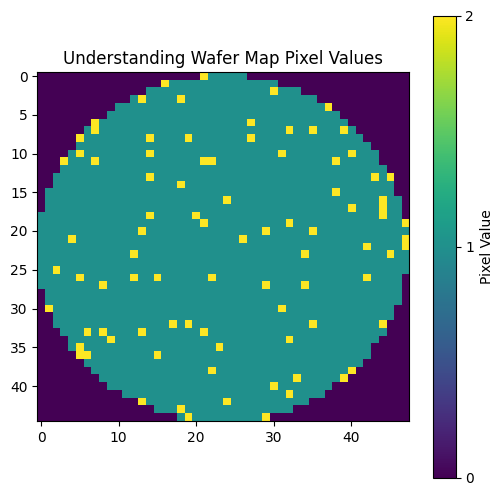

In [13]:
plt.figure(figsize=(6, 6))

plt.imshow(first_wafer, cmap="viridis", interpolation="nearest")

plt.title("Understanding Wafer Map Pixel Values")
plt.colorbar(ticks=[0, 1, 2], label="Pixel Value")

plt.show()

In [14]:
unique_values, counts = np.unique(first_wafer, return_counts=True)

for value, count in zip(unique_values, counts):
    print(f"Value {value}: {count} positions")

print("\nTotal positions:", first_wafer.size)

Value 0: 477 positions
Value 1: 1595 positions
Value 2: 88 positions

Total positions: 2160


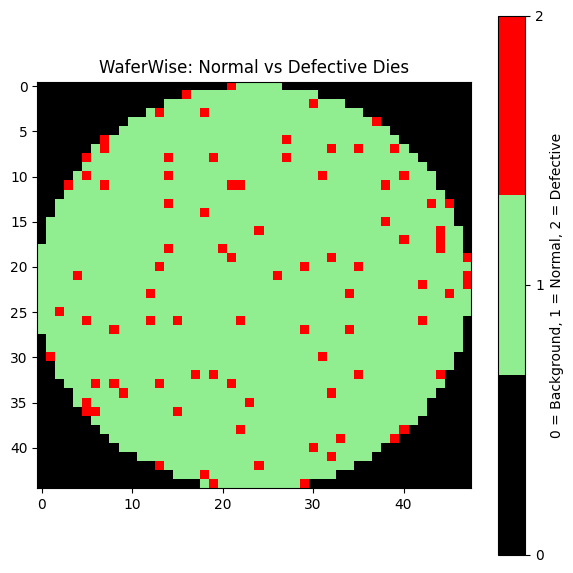

In [15]:
from matplotlib.colors import ListedColormap

wafer_cmap = ListedColormap([
    "black",       # 0 = Background
    "lightgreen",  # 1 = Normal
    "red"          # 2 = Defective
])

plt.figure(figsize=(7, 7))

plt.imshow(first_wafer, cmap=wafer_cmap, interpolation="nearest")

plt.title("WaferWise: Normal vs Defective Dies")
plt.colorbar(ticks=[0, 1, 2], label="0 = Background, 1 = Normal, 2 = Defective")

plt.show()

In [16]:
# Extract simple labels for easier filtering

df["failure_label"] = failure_labels

# Find the first wafer map for each defect category

defect_types = [
    "Edge-Ring",
    "Edge-Loc",
    "Center",
    "Loc",
    "Scratch",
    "Random",
    "Donut",
    "Near-full"
]

for defect in defect_types:
    matching = df[df["failure_label"] == defect]

    if len(matching) > 0:
        print(defect, ":", len(matching), "examples")


Edge-Ring : 9680 examples
Edge-Loc : 5189 examples
Center : 4294 examples
Loc : 3593 examples
Scratch : 1193 examples
Random : 866 examples
Donut : 555 examples
Near-full : 149 examples


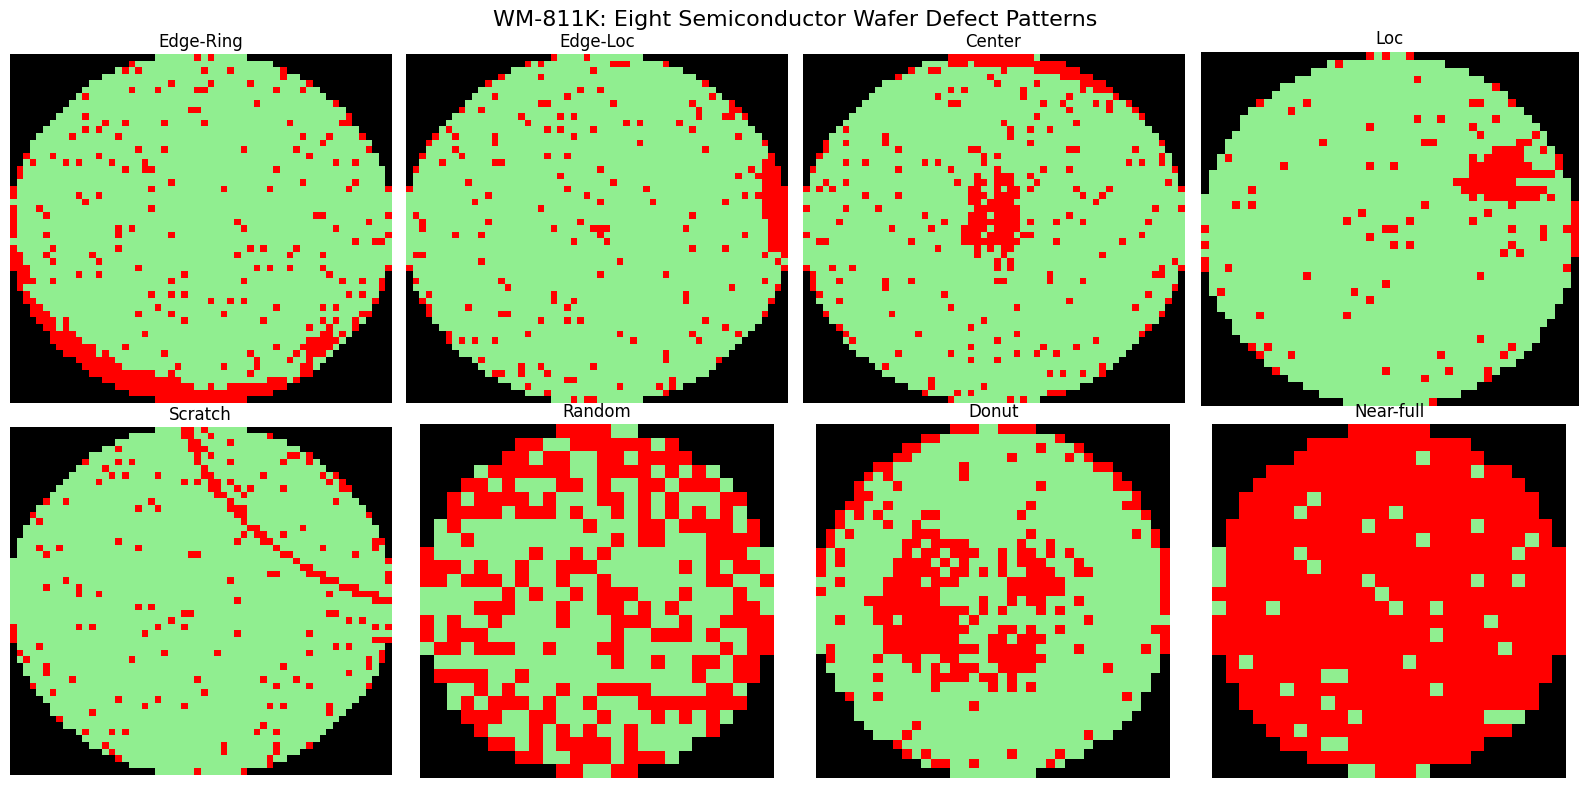

In [17]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, defect in zip(axes.flat, defect_types):

    # Select the first wafer belonging to this defect
    wafer = df[df["failure_label"] == defect].iloc[0]["waferMap"]

    ax.imshow(wafer, cmap=wafer_cmap, interpolation="nearest")
    ax.set_title(defect)
    ax.axis("off")

plt.suptitle("WM-811K: Eight Semiconductor Wafer Defect Patterns",
             fontsize=16)

plt.tight_layout()
plt.show()

In [18]:
# Inspect wafer map dimensions for each defect category

for defect in defect_types:

    matching = df[df["failure_label"] == defect]

    shapes = matching["waferMap"].apply(lambda x: x.shape)

    print(f"\n{defect}")
    print("Unique wafer dimensions:", shapes.nunique())
    print("Most common dimensions:")
    print(shapes.value_counts().head(5))


Edge-Ring
Unique wafer dimensions: 110
Most common dimensions:
waferMap
(38, 36)      2123
(53, 52)      1519
(63, 62)      1420
(69, 73)       483
(107, 150)     463
Name: count, dtype: int64

Edge-Loc
Unique wafer dimensions: 196
Most common dimensions:
waferMap
(39, 37)    473
(44, 41)    390
(25, 27)    355
(30, 34)    306
(26, 26)    296
Name: count, dtype: int64

Center
Unique wafer dimensions: 109
Most common dimensions:
waferMap
(25, 27)    2251
(34, 34)     246
(39, 37)     173
(40, 40)     173
(31, 31)     172
Name: count, dtype: int64

Loc
Unique wafer dimensions: 198
Most common dimensions:
waferMap
(26, 26)    297
(35, 31)    246
(30, 34)    241
(39, 37)    222
(39, 31)    182
Name: count, dtype: int64

Scratch
Unique wafer dimensions: 157
Most common dimensions:
waferMap
(29, 26)    80
(26, 26)    72
(30, 34)    69
(39, 37)    60
(52, 59)    54
Name: count, dtype: int64

Random
Unique wafer dimensions: 76
Most common dimensions:
waferMap
(41, 41)    125
(41, 51)     79
(

In [19]:
# Get dimensions of all labelled wafer maps

labelled_df = df[df["failure_label"].notna()].copy()

wafer_shapes = labelled_df["waferMap"].apply(
    lambda x: x.shape
)

heights = wafer_shapes.apply(lambda x: x[0])
widths = wafer_shapes.apply(lambda x: x[1])

print("Total labelled wafer maps:", len(labelled_df))

print("Smallest height:", heights.min())
print("Largest height:", heights.max())

print("Smallest width:", widths.min())
print("Largest width:", widths.max())

print("Number of unique dimensions:", wafer_shapes.nunique())

Total labelled wafer maps: 172950
Smallest height: 15
Largest height: 212
Smallest width: 3
Largest width: 204
Number of unique dimensions: 346


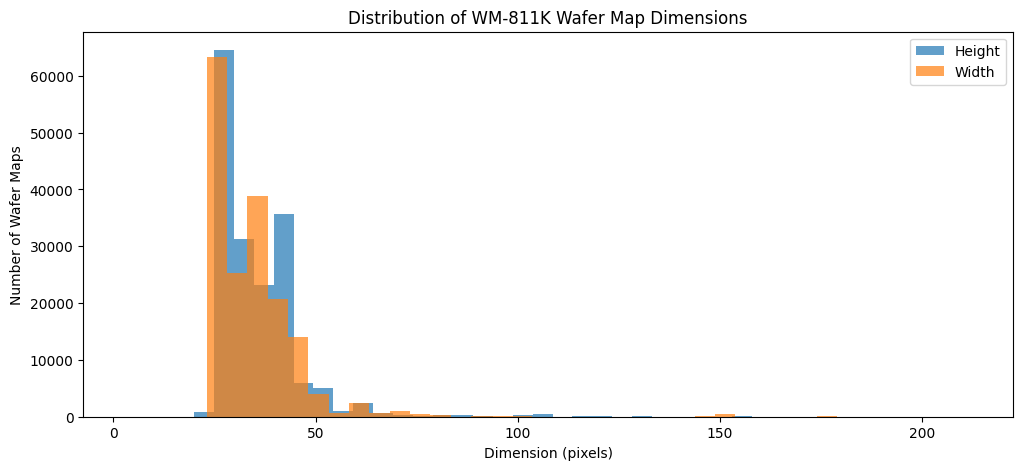

In [20]:
plt.figure(figsize=(12, 5))

plt.hist(heights, bins=40, alpha=0.7, label="Height")
plt.hist(widths, bins=40, alpha=0.7, label="Width")

plt.title("Distribution of WM-811K Wafer Map Dimensions")
plt.xlabel("Dimension (pixels)")
plt.ylabel("Number of Wafer Maps")

plt.legend()
plt.show()

In [21]:
# Create a clean table of labels and original splits

split_analysis = pd.DataFrame({
    "Defect": failure_labels,
    "Split": split_labels
})

# Remove records without defect labels
split_analysis = split_analysis.dropna(subset=["Defect"])

# Count defect categories in each split
split_table = pd.crosstab(
    split_analysis["Defect"],
    split_analysis["Split"]
)

display(split_table)

Split,Test,Training
Defect,,
Center,832,3462
Donut,146,409
Edge-Loc,2772,2417
Edge-Ring,1126,8554
Loc,1973,1620
Near-full,95,54
Random,257,609
Scratch,693,500
none,110701,36730


In [22]:
# Keep only labelled wafers with an assigned split

split_df = df[
    df["failure_label"].notna() &
    df["trianTestLabel"].apply(extract_label).isin(["Training", "Test"])
].copy()

# Extract original split labels
split_df["split"] = split_df["trianTestLabel"].apply(extract_label)

# Find unique manufacturing lots in each split
training_lots = set(
    split_df[split_df["split"] == "Training"]["lotName"].dropna()
)

test_lots = set(
    split_df[split_df["split"] == "Test"]["lotName"].dropna()
)

shared_lots = training_lots.intersection(test_lots)

print("Unique Training lots:", len(training_lots))
print("Unique Test lots:", len(test_lots))
print("Lots appearing in BOTH splits:", len(shared_lots))

Unique Training lots: 5809
Unique Test lots: 4953
Lots appearing in BOTH splits: 0


In [23]:
## Original Train-Test Split Analysis

The WM-811K dataset contains 172,950 labelled wafer maps.

The original labelled split contains:
- Training: 54,355 wafer maps
- Test: 118,595 wafer maps

Lot-level investigation:
- Unique Training lots: 5,809
- Unique Test lots: 4,953
- Shared lots: 0

No overlapping lot names were detected between the labelled
Training and Test subsets.

This is a useful observation for experimental design.
Further duplicate and leakage checks are still required.

SyntaxError: invalid decimal literal (470985571.py, line 3)

## Original Train-Test Split Analysis

The WM-811K dataset contains 172,950 labelled wafer maps.

The original labelled split contains:
- Training: 54,355 wafer maps
- Test: 118,595 wafer maps

### Lot-level investigation

- Unique Training lots: 5,809
- Unique Test lots: 4,953
- Shared lots: 0

No overlapping lot names were detected between the labelled Training and Test subsets.

This is a useful observation for experimental design. Further duplicate and leakage checks are still required.

In [24]:
import hashlib

# Calculate a unique fingerprint for each labelled wafer map

def wafer_hash(wafer):
    return hashlib.sha256(
        np.asarray(wafer).tobytes()
    ).hexdigest()

labelled_df["wafer_hash"] = labelled_df["waferMap"].apply(wafer_hash)

# Count duplicate wafer maps
duplicate_count = labelled_df["wafer_hash"].duplicated().sum()

print("Total labelled wafer maps:", len(labelled_df))
print("Duplicate wafer maps:", duplicate_count)
print("Unique wafer maps:", labelled_df["wafer_hash"].nunique())

Total labelled wafer maps: 172950
Duplicate wafer maps: 3252
Unique wafer maps: 169698


In [25]:
# Check duplicate wafer fingerprints across original splits

duplicate_split_check = labelled_df[
    labelled_df["wafer_hash"].duplicated(keep=False)
].merge(
    split_df[["waferMap", "split", "lotName"]],
    left_index=True,
    right_index=True,
    how="inner"
)

# Count fingerprints appearing in both splits
hash_split_counts = duplicate_split_check.groupby(
    "wafer_hash"
)["split"].nunique()

cross_split_duplicates = (hash_split_counts > 1).sum()

print("Duplicate fingerprints:", len(hash_split_counts))
print("Duplicate fingerprints across BOTH splits:",
      cross_split_duplicates)

Duplicate fingerprints: 3250
Duplicate fingerprints across BOTH splits: 3158


In [26]:
# Examine labels associated with duplicate wafer maps

duplicate_label_check = labelled_df[
    labelled_df["wafer_hash"].isin(
        labelled_df.loc[
            labelled_df["wafer_hash"].duplicated(keep=False),
            "wafer_hash"
        ]
    )
]

label_consistency = duplicate_label_check.groupby(
    "wafer_hash"
)["failure_label"].nunique()

print("Duplicate fingerprints examined:",
      len(label_consistency))

print("Fingerprints with conflicting labels:",
      (label_consistency > 1).sum())

print("Fingerprints with consistent labels:",
      (label_consistency == 1).sum())

Duplicate fingerprints examined: 3250
Fingerprints with conflicting labels: 14
Fingerprints with consistent labels: 3236


In [27]:
# Find wafer maps with conflicting labels

conflicting_hashes = label_consistency[
    label_consistency > 1
].index

conflicts = duplicate_label_check[
    duplicate_label_check["wafer_hash"].isin(conflicting_hashes)
]

for wafer_hash, group in conflicts.groupby("wafer_hash"):

    print("\nWafer fingerprint:", wafer_hash[:16])

    print(
        group[["failure_label", "lotName", "waferIndex"]]
        .to_string(index=False)
    )

    print("-" * 50)


Wafer fingerprint: 0d53f5735e2d1f01
failure_label  lotName  waferIndex
       Center   lot240         7.0
          Loc lot40481        24.0
--------------------------------------------------

Wafer fingerprint: 18d3e97439cb756c
failure_label  lotName  waferIndex
     Edge-Loc   lot234         8.0
         none lot40470         4.0
--------------------------------------------------

Wafer fingerprint: 1b1edfb0c2862e36
failure_label  lotName  waferIndex
         none   lot127        12.0
          Loc lot40489         3.0
--------------------------------------------------

Wafer fingerprint: 1f159da943e278cd
failure_label  lotName  waferIndex
       Center   lot105        12.0
         none lot40531        14.0
--------------------------------------------------

Wafer fingerprint: 2c52a5f0732e82ae
failure_label  lotName  waferIndex
         none   lot287        20.0
     Edge-Loc lot40579         3.0
--------------------------------------------------

Wafer fingerprint: 34c3a624aa2a369

## Duplicate Wafer Map and Label Consistency Analysis

An exact duplicate analysis was performed on the 172,950 labelled wafer maps using SHA-256 fingerprints.

Findings:
- Duplicate occurrences detected: 3,252
- Unique wafer map fingerprints: 169,698
- Duplicate fingerprints examined: 3,250
- Duplicate fingerprints appearing across both original splits: 3,158
- Fingerprints with consistent labels: 3,236
- Fingerprints with conflicting labels: 14

The 14 conflicting fingerprints were inspected. They contain identical wafer map arrays associated with different defect labels, manufacturing lots and wafer indices.

These cases require further investigation. Identical encoded maps do not necessarily represent the same physical wafer, and conflicting labels should not automatically be treated as annotation errors.

Further data-quality checks are required before defining the final experimental dataset.

In [28]:
# Attach wafer fingerprints to the original split information

split_hash_df = split_df.join(
    labelled_df["wafer_hash"],
    how="inner"
)

# Identify fingerprints appearing in both splits

split_counts = split_hash_df.groupby(
    "wafer_hash"
)["split"].nunique()

cross_split_hashes = split_counts[
    split_counts > 1
].index

# Retrieve all records belonging to these fingerprints

affected_records = split_hash_df[
    split_hash_df["wafer_hash"].isin(cross_split_hashes)
]

print("Cross-split duplicate fingerprints:",
      len(cross_split_hashes))

print("\nAffected Training records:",
      (affected_records["split"] == "Training").sum())

print("Affected Test records:",
      (affected_records["split"] == "Test").sum())

print("Total affected records:",
      len(affected_records))

Cross-split duplicate fingerprints: 3158

Affected Training records: 3159
Affected Test records: 3158
Total affected records: 6317


In [29]:
total_original_records = len(split_hash_df)

affected_percentage = (
    len(affected_records) / total_original_records
) * 100

print("Total records in original labelled splits:",
      total_original_records)

print("Affected records:", len(affected_records))

print("Percentage affected:",
      round(affected_percentage, 2), "%")

Total records in original labelled splits: 172950
Affected records: 6317
Percentage affected: 3.65 %


In [30]:
print("AFFECTED RECORDS BY DEFECT CATEGORY")

print(
    affected_records["failure_label"]
    .value_counts()
)

print("\nAFFECTED RECORDS BY ORIGINAL SPLIT")

print(
    pd.crosstab(
        affected_records["failure_label"],
        affected_records["split"]
    )
)

AFFECTED RECORDS BY DEFECT CATEGORY
failure_label
none         6121
Edge-Loc       67
Loc            39
Random         28
Scratch        22
Edge-Ring      14
Center         13
Near-full      13
Name: count, dtype: int64

AFFECTED RECORDS BY ORIGINAL SPLIT
split          Test  Training
failure_label                
Center            6         7
Edge-Loc         37        30
Edge-Ring         6         8
Loc              21        18
Near-full         6         7
Random           14        14
Scratch          11        11
none           3057      3064


In [31]:
# Total records in each defect category
total_by_class = split_hash_df["failure_label"].value_counts()

# Affected records in each defect category
affected_by_class = affected_records["failure_label"].value_counts()

# Calculate percentage affected within each category
class_impact = pd.DataFrame({
    "Total Records": total_by_class,
    "Affected Records": affected_by_class
}).fillna(0)

class_impact["Affected Percentage"] = (
    class_impact["Affected Records"] /
    class_impact["Total Records"] * 100
)

display(
    class_impact.sort_values(
        "Affected Percentage",
        ascending=False
    ).round(2)
)

,Total Records,Affected Records,Affected Percentage
failure_label,,,
Near-full,149,13.0,8.72
none,147431,6121.0,4.15
Random,866,28.0,3.23
Scratch,1193,22.0,1.84
Edge-Loc,5189,67.0,1.29
Loc,3593,39.0,1.09
Center,4294,13.0,0.30
Edge-Ring,9680,14.0,0.14
Donut,555,0.0,0.00


## Class-wise Impact of Cross-Split Duplicates

The 6,317 records associated with cross-split duplicate fingerprints were analysed by defect category.

Key findings:

- Near-full: 13 of 149 records affected (8.72%).
- none: 6,121 of 147,431 records affected (4.15%).
- Random: 28 of 866 records affected (3.23%).
- Donut: No affected records detected.

Near-full has the highest proportional impact despite having relatively few affected records.

This finding highlights the importance of protecting rare defect categories when constructing a new experimental dataset.

The original split will not automatically be assumed to be suitable for final model evaluation.